# Stage 3: Is it real or noise?

**Business question (Head of Customer Support):** *Which products cause the most problems, and is it the product's fault or our service?*

Stage 2 (SQL) found three differences that looked interesting. This notebook tests whether they are **statistically real** or could simply be **chance**, before anyone acts on them:

| # | Stage 2 claim | Test |
|---|---|---|
| 1 | Samsung Galaxy has a much higher defect share (49.5% vs 37.4%) | Chi-square, two-proportion z-test, Bonferroni, permutation |
| 2 | Critical tickets are stuck almost as often as Low ones | Chi-square, two-proportion z-test |
| 3 | Satisfaction differs by product (Fitbit Versa lowest at 2.54) | Chi-square on the rating distribution |

**Significance level:** α = 0.05, fixed before running any test.
**Data:** `data/clean/tickets_clean.csv` (output of Stage 1). See `docs/data_quality_log.md` for every cleaning decision.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ALPHA = 0.05
SEED = 42
DATA = Path("../data/clean/tickets_clean.csv")
IMAGES = Path("../images")

pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Load the data and check it matches Stage 2

Two helper columns make the tests simpler:
- `is_defect`: the ticket's issue category is *Product defect*
- `is_backlog`: the ticket is not closed yet (Open or Pending Customer Response)

In [2]:
df = pd.read_csv(DATA, parse_dates=["purchase_date", "first_response_at", "resolved_at"])
df["is_defect"] = df["issue_category"].eq("Product defect")
df["is_backlog"] = df["ticket_status"].ne("Closed")

# Sanity checks: the same numbers as Stage 1 and Stage 2
assert len(df) == 8469
assert df["csat"].notna().sum() == 2769
assert df["is_defect"].sum() == 3171
assert df["is_backlog"].sum() == 5700

overall_defect = df["is_defect"].mean()
print(f"Tickets: {len(df):,}")
print(f"Overall defect share: {overall_defect:.1%}")
print(f"Overall backlog share: {df['is_backlog'].mean():.1%}")
print(f"Rated (closed) tickets: {df['csat'].notna().sum():,}")

Tickets: 8,469
Overall defect share: 37.4%
Overall backlog share: 67.3%
Rated (closed) tickets: 2,769


## 2. Why testing is needed: what does pure chance look like?

Imagine every product had **exactly the same** true defect rate (37.4%). Would they all show 37.4%? No. With about 200 tickets each, chance alone spreads them out. The cell below simulates that world, using each product's real ticket count.

In [3]:
rng = np.random.default_rng(SEED)
tickets_per_product = df["product"].value_counts()
simulated = rng.binomial(tickets_per_product.values, overall_defect) / tickets_per_product.values
real = df.groupby("product")["is_defect"].mean()

print(f"Simulated (no real differences): {simulated.min():.1%} to {simulated.max():.1%}")
print(f"Real data:                       {real.min():.1%} to {real.max():.1%}")

Simulated (no real differences): 32.5% to 43.3%
Real data:                       31.0% to 49.5%


Even when no product is truly different, the simulated defect shares spread over a wide range. So a product can look "worse" without being worse. The tests below measure **how surprising** each real difference would be if it were only chance. That measure is the **p-value**: below 0.05 we call the difference significant.

## 3. Test 1: Is any product's defect share really different?

### 3a. Overall: does defect share depend on the product at all?
**Chi-square test of independence** on a product × defect table (42 × 2).
- H0: defect share is the same for every product; the differences are chance.
- H1: defect share depends on the product.

In [4]:
defect_table = pd.crosstab(df["product"], df["is_defect"])
chi2, p, dof, _ = stats.chi2_contingency(defect_table)
print(f"Chi-square = {chi2:.1f}, df = {dof}, p = {p:.3f}")
print("Significant" if p < ALPHA else "Not significant: no evidence that defect share depends on product in general")

Chi-square = 48.7, df = 41, p = 0.192
Not significant: no evidence that defect share depends on product in general


### 3b. Samsung Galaxy vs every other product
The overall test looks at all 42 products at once and can miss a single outlier. So Samsung Galaxy is tested on its own with a **two-proportion z-test**.

In [5]:
def two_proportion_ztest(successes_a, n_a, successes_b, n_b):
    """Two-sided z-test for the difference between two proportions (pooled standard error)."""
    p_a, p_b = successes_a / n_a, successes_b / n_b
    pooled = (successes_a + successes_b) / (n_a + n_b)
    se = np.sqrt(pooled * (1 - pooled) * (1 / n_a + 1 / n_b))
    z = (p_a - p_b) / se
    return p_a, p_b, z, 2 * stats.norm.sf(abs(z))


is_samsung = df["product"].eq("Samsung Galaxy")
p_a, p_b, z, p = two_proportion_ztest(
    df.loc[is_samsung, "is_defect"].sum(), is_samsung.sum(),
    df.loc[~is_samsung, "is_defect"].sum(), (~is_samsung).sum(),
)
print(f"Samsung Galaxy: {p_a:.1%} (n = {is_samsung.sum()})  vs  others: {p_b:.1%} (n = {(~is_samsung).sum():,})")
print(f"z = {z:.2f}, p = {p:.4f}")

Samsung Galaxy: 49.5% (n = 194)  vs  others: 37.2% (n = 8,275)
z = 3.51, p = 0.0005


### 3c. Correcting for 42 comparisons (Bonferroni)
We did not choose Samsung Galaxy in advance; we picked it *because* it was the highest of 42 products. Testing 42 products at α = 0.05 would make about 2 of them look significant by chance alone. The **Bonferroni correction** multiplies the p-value by the number of comparisons.

In [6]:
n_products = df["product"].nunique()
p_bonferroni = min(1.0, p * n_products)
print(f"Comparisons: {n_products}")
print(f"Bonferroni-adjusted p = {p_bonferroni:.3f}")
print("Still significant after correction" if p_bonferroni < ALPHA else "Not significant after correction")

Comparisons: 42
Bonferroni-adjusted p = 0.019
Still significant after correction


### 3d. Permutation check (no formulas)
A second way to answer the same question: shuffle the defect labels randomly across all tickets, which destroys any real link between product and defects, and see how often **some** product still reaches 49.5%. Repeated 2,000 times.

In [7]:
codes, product_names = pd.factorize(df["product"])
counts = np.bincount(codes)
labels = df["is_defect"].to_numpy(dtype=float)
samsung_share = df.loc[is_samsung, "is_defect"].mean()

rng = np.random.default_rng(SEED)
max_shares = np.array([
    (np.bincount(codes, weights=rng.permutation(labels)) / counts).max()
    for _ in range(2000)
])
p_perm = (max_shares >= samsung_share).mean()
print(f"Shuffles where some product reached {samsung_share:.1%}: {p_perm:.1%}")

Shuffles where some product reached 49.5%: 1.5%


### 3e. Funnel plot
Each dot is a product. The bands show how far from the 37.4% average a product can land **by chance**, given its number of tickets. Dots outside the outer (Bonferroni) band are unlikely to be chance even after correcting for 42 comparisons.

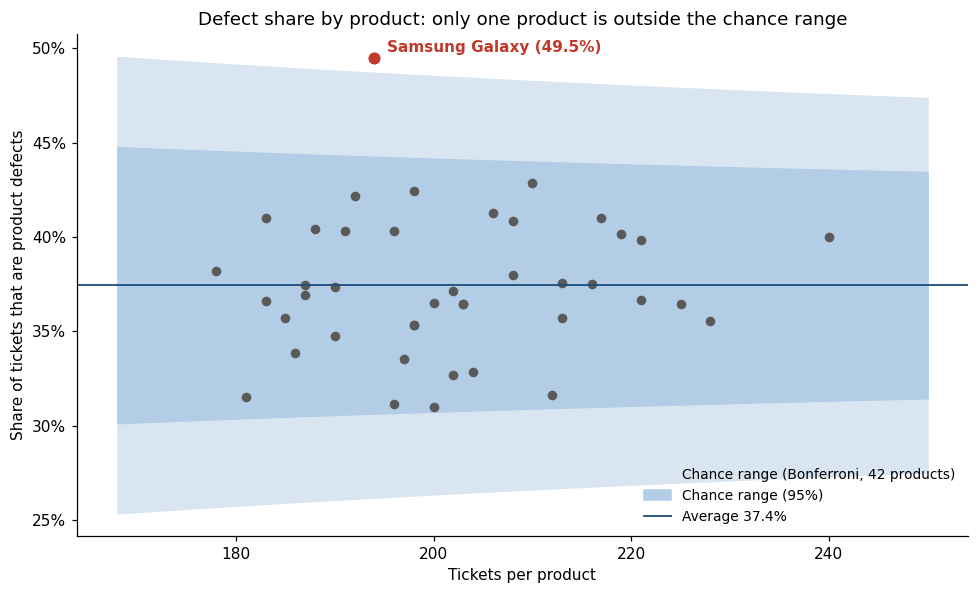

Products outside the Bonferroni band: ['Samsung Galaxy']


In [8]:
by_product = df.groupby("product").agg(tickets=("is_defect", "size"), defect_share=("is_defect", "mean"))
n_grid = np.linspace(by_product["tickets"].min() - 10, by_product["tickets"].max() + 10, 200)
se_grid = np.sqrt(overall_defect * (1 - overall_defect) / n_grid)
z_95 = stats.norm.ppf(1 - ALPHA / 2)
z_bonf = stats.norm.ppf(1 - ALPHA / (2 * n_products))

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.fill_between(n_grid, overall_defect - z_bonf * se_grid, overall_defect + z_bonf * se_grid,
                color="#d9e6f2", label="Chance range (Bonferroni, 42 products)")
ax.fill_between(n_grid, overall_defect - z_95 * se_grid, overall_defect + z_95 * se_grid,
                color="#b3cde6", label="Chance range (95%)")
ax.axhline(overall_defect, color="#1f4e79", lw=1.2, label=f"Average {overall_defect:.1%}")

outside = (by_product["defect_share"] - overall_defect).abs() > z_bonf * np.sqrt(
    overall_defect * (1 - overall_defect) / by_product["tickets"])
ax.scatter(by_product.loc[~outside, "tickets"], by_product.loc[~outside, "defect_share"], color="#5a5a5a", s=28)
ax.scatter(by_product.loc[outside, "tickets"], by_product.loc[outside, "defect_share"], color="#c0392b", s=48, zorder=3)
for name, row in by_product[outside].iterrows():
    ax.annotate(f"{name} ({row['defect_share']:.1%})", (row["tickets"], row["defect_share"]),
                xytext=(8, 4), textcoords="offset points", color="#c0392b", fontsize=10, weight="bold")

ax.set_title("Defect share by product: only one product is outside the chance range")
ax.set_xlabel("Tickets per product")
ax.set_ylabel("Share of tickets that are product defects")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(loc="lower right", frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(IMAGES / "stage3_defect_funnel.png", dpi=150)
plt.show()
print("Products outside the Bonferroni band:", list(by_product[outside].index))

### Conclusion: Test 1
- **Overall**, there is no evidence that defect share depends on the product: most of the spread between products is what chance would produce.
- **Samsung Galaxy is the exception.** It is significant on its own, it stays significant after correcting for 42 comparisons, and random shuffling rarely produces a product this extreme.
- **For the Head of Support:** Samsung Galaxy is the one product worth escalating to the product team. The other "high-defect" products from Stage 2 (Sony 4K HDR TV, Google Nest) are within the chance range.

## 4. Test 2: Does priority change the backlog?

### 4a. Overall: does the backlog share depend on priority?
**Chi-square test** on priority × backlog (4 × 2).

In [9]:
priority_order = ["Critical", "High", "Medium", "Low"]
backlog_table = pd.crosstab(df["priority"], df["is_backlog"]).loc[priority_order]
chi2, p, dof, _ = stats.chi2_contingency(backlog_table)
print(f"Chi-square = {chi2:.1f}, df = {dof}, p = {p:.3f}")
print("Significant" if p < ALPHA else "Not significant: no evidence that priority changes the backlog share")

Chi-square = 6.2, df = 3, p = 0.102
Not significant: no evidence that priority changes the backlog share


### 4b. Critical vs Low

In [10]:
crit = df["priority"].eq("Critical")
low = df["priority"].eq("Low")
p_a, p_b, z, p = two_proportion_ztest(
    df.loc[crit, "is_backlog"].sum(), crit.sum(),
    df.loc[low, "is_backlog"].sum(), low.sum(),
)
n_pairs = 6  # Critical-High, Critical-Medium, Critical-Low, High-Medium, High-Low, Medium-Low
print(f"Critical: {p_a:.1%} backlog  vs  Low: {p_b:.1%} backlog")
print(f"z = {z:.2f}, p = {p:.3f}, Bonferroni-adjusted (6 pairs) p = {min(1, p * n_pairs):.2f}")

Critical: 65.9% backlog  vs  Low: 68.8% backlog
z = -1.99, p = 0.047, Bonferroni-adjusted (6 pairs) p = 0.28


The raw p-value is just under 0.05, but this is **not** a finding. The overall test (4a) is not significant, and with 6 possible priority pairs the corrected p-value is far above 0.05. Treating it as significant would be cherry-picking.

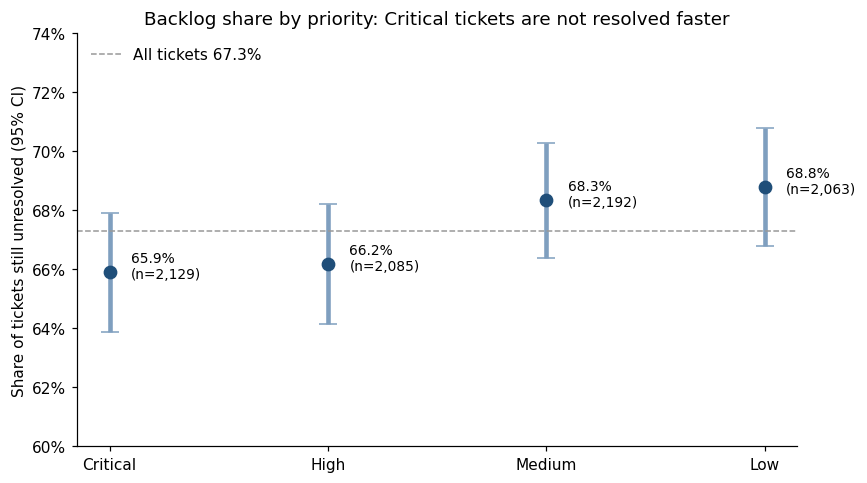

In [11]:
summary = df.groupby("priority")["is_backlog"].agg(["mean", "size"]).loc[priority_order]
summary["ci"] = z_95 * np.sqrt(summary["mean"] * (1 - summary["mean"]) / summary["size"])

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(summary.index, summary["mean"], yerr=summary["ci"], fmt="o", color="#1f4e79",
            ecolor="#7f9fbf", elinewidth=3, capsize=6, markersize=8)
for i, (share, n) in enumerate(zip(summary["mean"], summary["size"])):
    ax.annotate(f"{share:.1%}\n(n={n:,})", (i, share), xytext=(14, -4), textcoords="offset points", fontsize=9)
ax.axhline(df["is_backlog"].mean(), color="#999999", ls="--", lw=1, label=f"All tickets {df['is_backlog'].mean():.1%}")
ax.set_title("Backlog share by priority: Critical tickets are not resolved faster")
ax.set_ylabel("Share of tickets still unresolved (95% CI)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylim(0.60, 0.74)
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(IMAGES / "stage3_backlog_priority_ci.png", dpi=150)
plt.show()

### Conclusion: Test 2
- There is **no evidence that priority changes the backlog**. All four confidence intervals overlap.
- **For the Head of Support:** this *is* the finding. If prioritisation worked, Critical tickets would clear clearly faster than Low ones; they don't. The Critical label is not changing how work gets done.
- Wording matters: this does not *prove* the backlog is identical across priorities. It shows the data gives no evidence of a difference.

## 5. Test 3: Do satisfaction ratings differ by product or channel?

CSAT is a 1–5 rating, so it is treated as a **category**: the test compares the whole distribution of ratings, not just the mean. Closed tickets only (n = 2,769).

In [12]:
rated = df.dropna(subset=["csat"])

for column in ["product", "channel"]:
    table = pd.crosstab(rated[column], rated["csat"])
    chi2, p, dof, _ = stats.chi2_contingency(table)
    verdict = "significant" if p < ALPHA else "not significant"
    print(f"{column:8s} x csat: chi-square = {chi2:.1f}, df = {dof}, p = {p:.3f} -> {verdict}")

product  x csat: chi-square = 175.7, df = 164, p = 0.253 -> not significant
channel  x csat: chi-square = 11.7, df = 12, p = 0.467 -> not significant


In [13]:
csat_by_product = rated.groupby("product")["csat"].agg(avg_csat="mean", n="size").sort_values("avg_csat")
pd.concat([csat_by_product.head(3), csat_by_product.tail(3)]).round(2)

,avg_csat,n
product,,
Fitbit Versa Smartwatch,2.54,63
Sony Xperia,2.69,78
GoPro Action Camera,2.75,59
Garmin Forerunner,3.21,70
Google Pixel,3.22,69
Dyson Vacuum Cleaner,3.22,59


### Conclusion: Test 3
- There is **no evidence** that product or channel affects satisfaction ratings.
- Fitbit Versa Smartwatch's 2.54 (n = 63) is the lowest average, but with so few ratings it is consistent with chance.
- **For the Head of Support:** satisfaction looks flat across products and channels in this data. No product should be singled out on CSAT alone.

## 6. Verdict on every Stage 2 claim

In [14]:
verdicts = pd.DataFrame([
    ["Samsung Galaxy has a higher defect share", "Two-proportion z-test + Bonferroni (42)", "≈ 0.02 (adjusted)", "Real"],
    ["Defect share differs across products in general", "Chi-square 42×2", "≈ 0.19", "No evidence"],
    ["Priority changes the backlog share", "Chi-square 4×2", "≈ 0.10", "No evidence (Critical not faster)"],
    ["Satisfaction differs by product", "Chi-square 42×5", "≈ 0.25", "No evidence"],
    ["Satisfaction differs by channel", "Chi-square 4×5", "≈ 0.47", "No evidence"],
], columns=["Stage 2 claim", "Test", "p-value", "Verdict"])
verdicts

,Stage 2 claim,Test,p-value,Verdict
0,Samsung Galaxy has a higher defect share,Two-proportion z-test + Bonferroni (42),≈ 0.02 (adjusted),Real
1,Defect share differs across products in general,Chi-square 42×2,≈ 0.19,No evidence
2,Priority changes the backlog share,Chi-square 4×2,≈ 0.10,No evidence (Critical not faster)
3,Satisfaction differs by product,Chi-square 42×5,≈ 0.25,No evidence
4,Satisfaction differs by channel,Chi-square 4×5,≈ 0.47,No evidence


**Summary for the Head of Support**
1. **Escalate Samsung Galaxy to the product team.** Its defect share (49.5%) is the only product difference that survives testing.
2. **Fix prioritisation.** Critical tickets are not cleared faster than Low ones; the priority label is not changing how work gets done.
3. **Don't chase satisfaction by product or channel.** In this data the differences are within chance.

*Caveat:* the dataset is synthetic (see the data quality log, #5), which is why most patterns are flat. The method (test before acting, correct for multiple comparisons) is what carries over to real data.